# CS5785 Midterm Project 2026 — Clinical-trial stopping reasons & outcomes

This notebook contains every experiment, table and figure used in the report.
It builds on the course starter notebook (baseline cells are kept and marked "baseline").

* **Part 1** – semi-supervised multi-label prediction of five stopping reasons from 150-d reason embeddings,
  where 1,014 of 1,171 training trials have their labels masked.
* **Part 2** – per-phase binary prediction of trial success, an error analysis by stopping reason,
  and an improved classifier.

Data CSVs are expected in `data/`; figures are written to `figures/`; Kaggle files to the notebook folder.
Runtime: ~5–10 minutes on a laptop CPU.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.special import logsumexp

from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.semi_supervised import LabelSpreading
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import (f1_score, roc_auc_score, average_precision_score, log_loss,
                             silhouette_score, adjusted_rand_score)

DATA = "data/"
FIG = "figures/"
SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
reason_train = pd.read_csv(DATA + "part1_train.csv")
reason_val = pd.read_csv(DATA + "part1_val.csv")
reason_test = pd.read_csv(DATA + "part1_test.csv")

outcome_train = pd.read_csv(DATA + "outcome_train.csv")
outcome_val = pd.read_csv(DATA + "outcome_val.csv")
outcome_test = pd.read_csv(DATA + "outcome_test.csv")

pathway_catalog = pd.read_csv(DATA + "pathway_catalog.csv")
print(reason_train.shape, reason_val.shape, reason_test.shape)
print(outcome_train.shape, outcome_val.shape, outcome_test.shape)

(1171, 166) (78, 166) (312, 161)
(8037, 15) (1013, 15) (1500, 14)


# Part 1: Stopping reasons

## 1.1 Data preparation and exploration
We standardise the 150 embedding columns with statistics from the training file (labeled + unlabeled).

In [3]:
labels = ["Safety", "Funding", "Efficacy", "Recruitment", "Other"]
features = [f"emb_{i}" for i in range(150)]
labeled = (reason_train[labels] != -100).all(axis=1).values

scaler = StandardScaler()
X_train = scaler.fit_transform(reason_train[features])
X_val = scaler.transform(reason_val[features])
X_test = scaler.transform(reason_test[features])

y_train = reason_train.loc[labeled, labels]
y_val = reason_val[labels]

XL, YL = X_train[labeled], y_train.values             # labeled training trials
XU = np.vstack([X_train[~labeled], X_test])            # unlabeled pool: masked train + test features (transductive)
Yva = y_val.values

print("Labeled trials:", labeled.sum())
print("Unlabeled trials:", (~labeled).sum())
print("Unlabeled pool used by the semi-supervised methods:", len(XU))

Labeled trials: 157
Unlabeled trials: 1014
Unlabeled pool used by the semi-supervised methods: 1326


             labeled train (157)  val (78)
Safety                     0.102     0.115
Funding                    0.051     0.051
Efficacy                   0.108     0.179
Recruitment                0.643     0.641
Other                      0.159     0.128

Labels per trial (labeled): {1: 147, 2: 10} | (val): {1: 69, 2: 9}


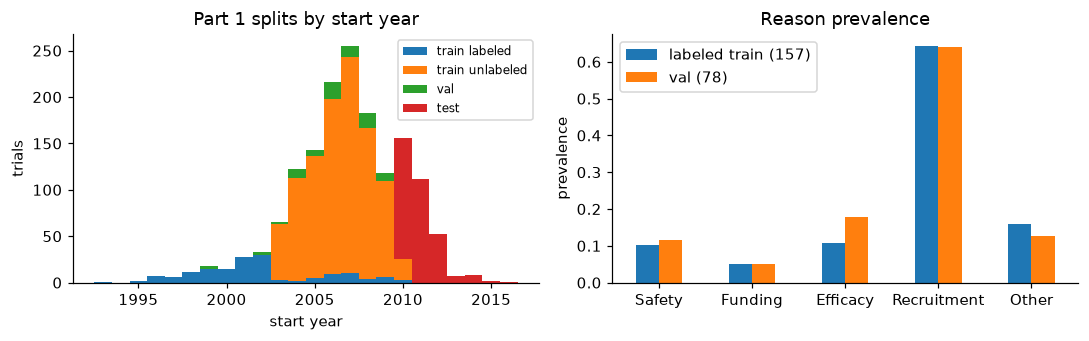

In [4]:
prev = pd.DataFrame({"labeled train (157)": y_train.mean(), "val (78)": y_val.mean()}).round(3)
prev["labels/trial (lab)"] = ""
print(prev.drop(columns="labels/trial (lab)"))
print("\nLabels per trial (labeled):", y_train.sum(axis=1).value_counts().to_dict(),
      "| (val):", y_val.sum(axis=1).value_counts().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
bins = np.arange(1992.5, 2017.5)
ax[0].hist([reason_train.start_year[labeled], reason_train.start_year[~labeled], reason_val.start_year, reason_test.start_year],
           bins=bins, stacked=True, label=["train labeled", "train unlabeled", "val", "test"])
ax[0].set_xlabel("start year"); ax[0].set_ylabel("trials"); ax[0].legend(fontsize=8); ax[0].set_title("Part 1 splits by start year")
prev.drop(columns="labels/trial (lab)").plot.bar(ax=ax[1], rot=0)
ax[1].set_ylabel("prevalence"); ax[1].set_title("Reason prevalence")
plt.tight_layout(); plt.savefig(FIG + "p1_data.png", bbox_inches="tight"); plt.show()

Almost every trial has exactly one reason (147/157 labeled, 69/78 val), and Recruitment dominates (~64%).
Labeled trials are concentrated before 2003, while the test trials start in 2010–2016, so label priors shift.

## 1.2 Logistic regression baseline (starter code)

In [5]:
reason_model = OneVsRestClassifier(
    LogisticRegression(max_iter=500, solver="liblinear", random_state=42)
)
reason_model.fit(X_train[labeled], y_train)
val_pred = reason_model.predict(X_val)

print("Sample-wise F1:", round(f1_score(y_val, val_pred, average="samples", zero_division=0), 4))
print("Macro F1:", round(f1_score(y_val, val_pred, average="macro", zero_division=0), 4))

per_label_f1 = f1_score(y_val, val_pred, average=None, zero_division=0)
pd.Series(per_label_f1, index=labels, name="F1").round(4)

Sample-wise F1: 0.8654
Macro F1: 0.7067


Safety         0.8571
Funding        0.2857
Efficacy       0.8276
Recruitment    0.9796
Other          0.5833
Name: F1, dtype: float64

## 1.3 Helpers

* `at_least_one` – every Part 1 trial was stopped for *some* reason, so if no label passes the 0.5 threshold we
  assign the most probable one. This alone fixes empty predictions, which score 0 in sample-wise F1.
* `fit_lr` – five independent (one-vs-rest) L2 logistic regressions with `class_weight="balanced"` (Funding has
  only 8 positive labeled trials) and optional per-sample weights, used to down-weight pseudo-labels.
* `evaluate` – we report **validation** scores (the official selection set) and, because the validation set has only
  78 trials (one trial ≈ 1.3 points of sample-F1), also **2×5-fold cross-validation over the 235 labeled trials
  (train-labeled ∪ val)**. In each CV fold the held-out labels are hidden and every method sees the same unlabeled pool.

In [6]:
def at_least_one(P, thr=0.5):
    Y = (P >= thr).astype(int)
    empty = Y.sum(1) == 0
    Y[empty, P[empty].argmax(1)] = 1
    return Y


def fit_lr(X, Y, C=0.1, w=None, class_weight="balanced"):
    models = [LogisticRegression(C=C, max_iter=3000, class_weight=class_weight).fit(X, Y[:, j], sample_weight=w)
              for j in range(Y.shape[1])]
    return lambda Q: np.column_stack([m.predict_proba(Q)[:, 1] for m in models])


XP, YP = np.vstack([XL, X_val]), np.vstack([YL, Yva])
p1_results = []

def evaluate(name, method, cv=True, **kw):
    t = time.time()
    yv = at_least_one(method(XL, YL, XU, **kw)(X_val))
    row = {"method": name,
           "val sample-F1": f1_score(Yva, yv, average="samples", zero_division=0),
           "val macro-F1": f1_score(Yva, yv, average="macro", zero_division=0)}
    row.update({f"val F1 {l}": f for l, f in zip(labels, f1_score(Yva, yv, average=None, zero_division=0))})
    if cv:
        s, m = [], []
        for rep in range(2):
            for a, b in KFold(5, shuffle=True, random_state=rep).split(XP):
                yh = at_least_one(method(XP[a], YP[a], XU, **kw)(XP[b]))
                s.append(f1_score(YP[b], yh, average="samples", zero_division=0))
                m.append(f1_score(YP[b], yh, average="macro", zero_division=0))
        row.update({"CV sample-F1": np.mean(s), "CV macro-F1": np.mean(m)})
    p1_results.append(row)
    print(f"{name:48s} val s-F1={row['val sample-F1']:.4f} m-F1={row['val macro-F1']:.4f}"
          + (f" | CV s-F1={row['CV sample-F1']:.4f} m-F1={row['CV macro-F1']:.4f}" if cv else "")
          + f"  ({time.time()-t:.0f}s)")
    return row

## 1.4 Do the embeddings cluster by reason?
Before using clusters to propagate labels we check how well unsupervised structure lines up with the labels.
We fit K-means on L2-normalised, PCA-reduced embeddings of all 1,561 trials (no labels used) and measure
(i) silhouette and (ii) the *purity* of clusters with respect to the 235 labeled trials (fraction of labeled
members whose label-set equals the cluster's majority label-set).

 K   inertia  silhouette  label purity  ARI vs label-set
 2 1101.9639      0.1964        0.5830            0.0409
 3 1021.6371      0.1628        0.6043            0.1858
 5  888.6543      0.1641        0.6553            0.2032
 8  782.5156      0.1973        0.6979            0.1109
10  729.8401      0.2027        0.7149            0.1066
15  644.7810      0.2339        0.7574            0.1097
20  596.8597      0.2587        0.7660            0.0997
30  533.7547      0.2518        0.8340            0.0949
40  488.7865      0.2713        0.8553            0.0949
60  430.7658      0.2904        0.8426            0.0811
80  389.0059      0.3070        0.8723            0.0760
Majority-class purity (all Recruitment): 0.583


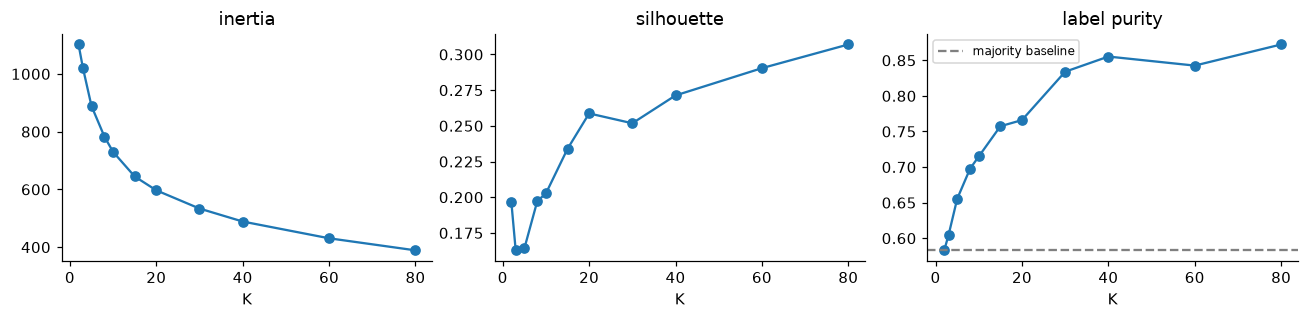

In [7]:
X_all = np.vstack([XL, XU, X_val])
Z_all = PCA(50, random_state=SEED).fit_transform(normalize(X_all))
labset = lambda Y: np.array(["+".join(l for l, v in zip(labels, r) if v) for r in Y])
lab_idx = np.r_[np.arange(len(XL)), np.arange(len(X_all) - len(X_val), len(X_all))]
lab_sets = labset(np.vstack([YL, Yva]))

rows = []
for K in [2, 3, 5, 8, 10, 15, 20, 30, 40, 60, 80]:
    km = KMeans(K, n_init=10, random_state=SEED).fit(Z_all)
    c = km.labels_[lab_idx]
    purity = sum(pd.Series(lab_sets[c == k]).value_counts().iloc[0] for k in np.unique(c)) / len(c)
    rows.append({"K": K, "inertia": km.inertia_, "silhouette": silhouette_score(Z_all, km.labels_),
                 "label purity": purity, "ARI vs label-set": adjusted_rand_score(lab_sets, c)})
km_diag = pd.DataFrame(rows).round(4)
print(km_diag.to_string(index=False))
print("Majority-class purity (all Recruitment):", round(pd.Series(lab_sets).value_counts().iloc[0] / len(lab_sets), 4))

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, col in zip(ax, ["inertia", "silhouette", "label purity"]):
    a.plot(km_diag.K, km_diag[col], "o-"); a.set_xlabel("K"); a.set_title(col)
ax[2].axhline(pd.Series(lab_sets).value_counts().iloc[0] / len(lab_sets), ls="--", c="gray", label="majority baseline")
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG + "p1_kmeans_diag.png", bbox_inches="tight"); plt.show()

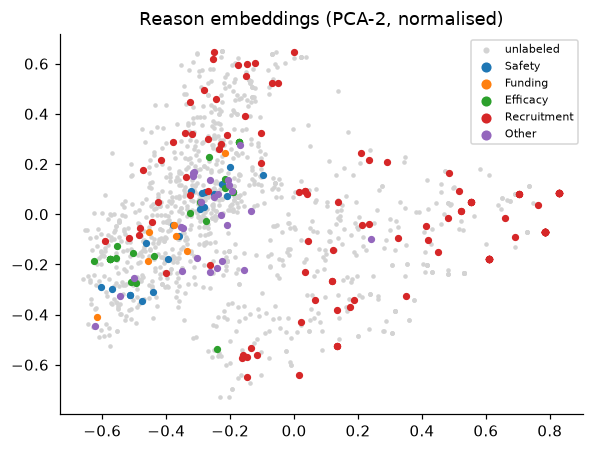

In [8]:
# 2-D PCA view of the embedding space coloured by the (single) label of labeled trials
Z2 = PCA(2, random_state=SEED).fit_transform(normalize(X_all))
fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.scatter(Z2[:, 0], Z2[:, 1], s=4, c="lightgray", label="unlabeled")
for l in labels:
    m = lab_sets == l
    ax.scatter(Z2[lab_idx][m, 0], Z2[lab_idx][m, 1], s=14, label=l)
ax.legend(fontsize=7, markerscale=1.5); ax.set_title("Reason embeddings (PCA-2, normalised)")
plt.tight_layout(); plt.savefig(FIG + "p1_pca2.png", bbox_inches="tight"); plt.show()

Silhouette values are low and no K gives a clear elbow: the embedding space has no strong cluster structure.
Purity rises with K only because small clusters become pure trivially. Recruitment trials form one large
dense region, while Safety and Efficacy partly overlap ("lack of efficacy" and "safety concerns" read alike).
So clusters on their own are a weak labeler, and we need to combine them with supervised signal.

## 1.5 Label-recovery methods

| id | method | unsupervised part |
|---|---|---|
| A | Supervised one-vs-rest LR on the 157 labeled trials | none (reference) |
| B | **K-means cluster-then-label**: each cluster's label vector = smoothed mean of its labeled members; unlabeled trials take their cluster's labels; LR retrained on labeled + pseudo-labeled (weight `w_u`) | K-means (k-means++, 10 restarts) |
| C | **K-means ∩ LR agreement**: pseudo-label only the unlabeled trials where the cluster vote and the supervised LR agree | K-means |
| D | **GMM soft labels**: diagonal-covariance GMM on PCA-20; unlabeled trials get soft labels from component posteriors; LR trained with fractional weights | GMM (EM) |
| E | **Semi-supervised GMM (Nigam-style EM)**: one Gaussian per label-set seen in the labeled data, shared (tied) covariance; labeled responsibilities fixed, unlabeled responsibilities from the E-step; then confident posteriors → pseudo-labels → LR | GMM with label-seeded EM |
| F | Self-training LR: repeatedly add unlabeled trials whose 5 probabilities are all confident | none (wrapper) |
| G | Label spreading (kNN graph, one run per label) | graph-based |
| H | Ensemble: mean probability of A, C and E | — |

In [9]:
def m_supervised(XL, YL, XU, C=0.1):
    return fit_lr(XL, YL, C)


def kmeans_cluster_labels(XL, YL, XU, K, npc, seed=SEED):
    Z = PCA(npc, random_state=seed).fit_transform(normalize(np.vstack([XL, XU])))
    c = KMeans(K, n_init=10, random_state=seed).fit_predict(Z)
    cl, cu = c[:len(XL)], c[len(XL):]
    prior = YL.mean(0)    # add-one smoothing toward the labeled prior for clusters with few/no labeled members
    CL = np.array([(YL[cl == k].sum(0) + prior) / ((cl == k).sum() + 1) for k in range(K)])
    return CL[cu]


def m_kmeans(XL, YL, XU, K=40, npc=50, C=0.1, wu=0.3):
    YU = at_least_one(kmeans_cluster_labels(XL, YL, XU, K, npc))
    return fit_lr(np.vstack([XL, XU]), np.vstack([YL, YU]), C, w=np.r_[np.ones(len(XL)), wu * np.ones(len(XU))])


def m_kmeans_agree(XL, YL, XU, K=20, npc=50, C=0.1, wu=1.0):
    Yc = at_least_one(kmeans_cluster_labels(XL, YL, XU, K, npc))
    Ys = at_least_one(fit_lr(XL, YL, C)(XU))
    keep = (Yc == Ys).all(1)
    return fit_lr(np.vstack([XL, XU[keep]]), np.vstack([YL, Ys[keep]]), C,
                  w=np.r_[np.ones(len(XL)), wu * np.ones(keep.sum())])


def m_gmm_soft(XL, YL, XU, K=20, npc=20, C=0.1, wu=0.5, seed=SEED):
    Z = PCA(npc, random_state=seed).fit_transform(np.vstack([XL, XU]))
    g = GaussianMixture(K, covariance_type="diag", reg_covar=1e-3, n_init=3, random_state=seed).fit(Z)
    R = g.predict_proba(Z); Rl, Ru = R[:len(XL)], R[len(XL):]
    prior = YL.mean(0)
    PU = Ru @ ((Rl.T @ YL + prior) / (Rl.sum(0)[:, None] + 1))    # soft label = posterior-weighted component label means
    Xd = np.vstack([XL, XU, XU]); models = []
    for j in range(5):   # soft labels via duplicated rows with fractional weights
        yd = np.r_[YL[:, j], np.ones(len(XU)), np.zeros(len(XU))]
        wd = np.r_[np.ones(len(XL)), wu * PU[:, j], wu * (1 - PU[:, j])] + 1e-9
        models.append(LogisticRegression(C=C, max_iter=3000, class_weight="balanced").fit(Xd, yd, sample_weight=wd))
    return lambda Q: np.column_stack([m.predict_proba(Q)[:, 1] for m in models])


def ss_gmm(XL, YL, XU, npc=20, lam=1.0, reg=1e-2, max_iter=100, tol=1e-5):
    """Semi-supervised GMM fit by EM. Components = label-sets present in the labeled data
    (5 single reasons + observed pairs), means initialised from labeled members, tied covariance.
    Labeled responsibilities are clamped to their true component; unlabeled ones are re-estimated
    every E-step and enter the M-step with weight `lam`. Stops when the relative change of the
    unlabeled log-likelihood < tol."""
    pca = PCA(npc, random_state=SEED).fit(np.vstack([XL, XU]))
    ZL, ZU = pca.transform(XL), pca.transform(XU)
    combos, cls = np.unique(YL, axis=0, return_inverse=True)
    K = len(combos); RL = np.eye(K)[cls.ravel()]; Z = np.vstack([ZL, ZU])

    def mstep(RU):
        R = np.vstack([RL, lam * RU]); Nk = R.sum(0) + 1e-6
        pi, mu = Nk / Nk.sum(), (R.T @ Z) / Nk[:, None]
        S = sum((R[:, k:k + 1] * (Z - mu[k])).T @ (Z - mu[k]) for k in range(K)) / Nk.sum() + reg * np.eye(npc)
        return pi, mu, np.linalg.inv(S), np.linalg.slogdet(S)[1]

    def logp(Zq, pi, mu, Si, ld):
        return np.column_stack([np.log(pi[k]) - 0.5 * (np.einsum("ij,jk,ik->i", Zq - mu[k], Si, Zq - mu[k]) + ld)
                                for k in range(K)])

    params = mstep(np.zeros((len(ZU), K)))       # initialise from labeled data only
    hist = []
    for it in range(max_iter):
        lp = logp(ZU, *params); ll = logsumexp(lp, 1).sum(); hist.append(ll)
        RU = np.exp(lp - logsumexp(lp, 1, keepdims=True))
        params = mstep(RU)
        if it > 0 and abs(hist[-1] - hist[-2]) < tol * abs(hist[-2]):
            break

    def predict(Q):
        lp = logp(pca.transform(Q), *params)
        return np.exp(lp - logsumexp(lp, 1, keepdims=True)) @ combos
    return predict, RU, combos, hist


def m_ss_gmm(XL, YL, XU, npc=20, lam=1.0):
    return ss_gmm(XL, YL, XU, npc=npc, lam=lam)[0]


def m_ss_gmm_lr(XL, YL, XU, npc=20, lam=1.0, conf=0.95, wu=0.3, C=0.1):
    _, RU, combos, _ = ss_gmm(XL, YL, XU, npc=npc, lam=lam)
    keep = RU.max(1) >= conf
    return fit_lr(np.vstack([XL, XU[keep]]), np.vstack([YL, combos[RU.argmax(1)][keep]]), C,
                  w=np.r_[np.ones(len(XL)), wu * np.ones(keep.sum())])


def m_self_train(XL, YL, XU, C=0.1, thr=0.95, rounds=5):
    X, Y, rem = XL, YL, np.arange(len(XU))
    for _ in range(rounds):
        P = fit_lr(X, Y, C)(XU[rem])
        conf = (np.abs(P - 0.5) * 2).min(1) >= thr
        if not conf.any(): break
        X, Y, rem = np.vstack([X, XU[rem[conf]]]), np.vstack([Y, at_least_one(P[conf])]), rem[~conf]
    return fit_lr(X, Y, C)


def m_label_spreading(XL, YL, XU, k=20, alpha=0.5):
    X = normalize(np.vstack([XL, XU])); models = []
    for j in range(5):
        y = np.r_[YL[:, j], -np.ones(len(XU), int)]
        models.append(LabelSpreading(kernel="knn", n_neighbors=k, alpha=alpha, max_iter=200).fit(X, y))
    return lambda Q: np.column_stack([m.predict_proba(normalize(Q))[:, 1] for m in models])


def m_ensemble(XL, YL, XU):
    fs = [m_supervised(XL, YL, XU), m_kmeans_agree(XL, YL, XU), m_ss_gmm_lr(XL, YL, XU)]
    return lambda Q: np.mean([f(Q) for f in fs], 0)

### Hyper-parameter sweeps
(Each line = validation + 2×5-fold CV.)

In [10]:
for C in [0.01, 0.1, 1, 10]:
    evaluate(f"A  supervised LR C={C}", m_supervised, C=C)

A  supervised LR C=0.01                          val s-F1=0.8590 m-F1=0.7458 | CV s-F1=0.8855 m-F1=0.7775  (0s)


A  supervised LR C=0.1                           val s-F1=0.8590 m-F1=0.7291 | CV s-F1=0.8957 m-F1=0.7979  (0s)


A  supervised LR C=1                             val s-F1=0.8697 m-F1=0.7616 | CV s-F1=0.8861 m-F1=0.7872  (1s)


A  supervised LR C=10                            val s-F1=0.8718 m-F1=0.7720 | CV s-F1=0.8833 m-F1=0.7828  (1s)


In [11]:
for K in [10, 20, 40, 80]:
    for wu in [0.3, 1.0]:
        evaluate(f"B  K-means cluster-then-label K={K} w_u={wu}", m_kmeans, K=K, wu=wu)

B  K-means cluster-then-label K=10 w_u=0.3       val s-F1=0.8013 m-F1=0.5292 | CV s-F1=0.8160 m-F1=0.6815  (4s)


B  K-means cluster-then-label K=10 w_u=1.0       val s-F1=0.7949 m-F1=0.5254 | CV s-F1=0.8113 m-F1=0.6620  (2s)


B  K-means cluster-then-label K=20 w_u=0.3       val s-F1=0.7944 m-F1=0.6275 | CV s-F1=0.8421 m-F1=0.7202  (3s)


B  K-means cluster-then-label K=20 w_u=1.0       val s-F1=0.8286 m-F1=0.6819 | CV s-F1=0.8241 m-F1=0.6805  (3s)


B  K-means cluster-then-label K=40 w_u=0.3       val s-F1=0.8162 m-F1=0.6963 | CV s-F1=0.8579 m-F1=0.7347  (3s)


B  K-means cluster-then-label K=40 w_u=1.0       val s-F1=0.7842 m-F1=0.6685 | CV s-F1=0.8472 m-F1=0.7153  (4s)


B  K-means cluster-then-label K=80 w_u=0.3       val s-F1=0.8440 m-F1=0.7295 | CV s-F1=0.8687 m-F1=0.7612  (3s)


B  K-means cluster-then-label K=80 w_u=1.0       val s-F1=0.8483 m-F1=0.7342 | CV s-F1=0.8482 m-F1=0.7326  (4s)


In [12]:
def m_cluster_vote(XL, YL, XU, K=40, npc=50):
    """pure clustering classifier: a query trial gets the label distribution of its K-means cluster."""
    def predict(Q):
        return kmeans_cluster_labels(XL, YL, np.vstack([XU, Q]), K, npc)[len(XU):]
    return predict

for K in [10, 20, 40, 80]:
    evaluate(f"B0 K-means cluster vote only K={K}", m_cluster_vote, K=K)
for K in [10, 20, 40]:
    evaluate(f"C  K-means ∩ LR agreement K={K}", m_kmeans_agree, K=K)

B0 K-means cluster vote only K=10                val s-F1=0.7735 m-F1=0.4076 | CV s-F1=0.7106 m-F1=0.3529  (1s)


B0 K-means cluster vote only K=20                val s-F1=0.7863 m-F1=0.4580 | CV s-F1=0.7688 m-F1=0.4803  (1s)


B0 K-means cluster vote only K=40                val s-F1=0.8462 m-F1=0.6844 | CV s-F1=0.8195 m-F1=0.6469  (2s)


B0 K-means cluster vote only K=80                val s-F1=0.7650 m-F1=0.5715 | CV s-F1=0.8348 m-F1=0.6803  (3s)


C  K-means ∩ LR agreement K=10                   val s-F1=0.8932 m-F1=0.7853 | CV s-F1=0.8850 m-F1=0.7610  (4s)


C  K-means ∩ LR agreement K=20                   val s-F1=0.8761 m-F1=0.7709 | CV s-F1=0.8818 m-F1=0.7688  (3s)


C  K-means ∩ LR agreement K=40                   val s-F1=0.8718 m-F1=0.7461 | CV s-F1=0.8967 m-F1=0.7972  (2s)


In [13]:
for K in [10, 20, 40]:
    evaluate(f"D  GMM soft labels K={K}", m_gmm_soft, K=K)
for npc in [10, 20, 40]:
    for lam in [0.0, 0.3, 1.0]:
        evaluate(f"E0 semi-sup GMM classifier npc={npc} λ={lam}", m_ss_gmm, npc=npc, lam=lam)
for npc in [20, 40]:
    for conf in [0.8, 0.95]:
        evaluate(f"E  semi-sup GMM → pseudo-labels → LR npc={npc} conf={conf}", m_ss_gmm_lr, npc=npc, conf=conf)

D  GMM soft labels K=10                          val s-F1=0.7419 m-F1=0.5535 | CV s-F1=0.7665 m-F1=0.5738  (4s)


D  GMM soft labels K=20                          val s-F1=0.7744 m-F1=0.6174 | CV s-F1=0.7924 m-F1=0.6305  (3s)


D  GMM soft labels K=40                          val s-F1=0.8239 m-F1=0.6689 | CV s-F1=0.7966 m-F1=0.6285  (6s)


E0 semi-sup GMM classifier npc=10 λ=0.0          val s-F1=0.8675 m-F1=0.6907 | CV s-F1=0.8447 m-F1=0.6368  (0s)


E0 semi-sup GMM classifier npc=10 λ=0.3          val s-F1=0.7457 m-F1=0.5624 | CV s-F1=0.8209 m-F1=0.6340  (3s)


E0 semi-sup GMM classifier npc=10 λ=1.0          val s-F1=0.7244 m-F1=0.5365 | CV s-F1=0.8060 m-F1=0.6118  (3s)


... (6 outputs left out)

E  semi-sup GMM → pseudo-labels → LR npc=20 conf=0.8 val s-F1=0.8376 m-F1=0.6832 | CV s-F1=0.8609 m-F1=0.6980  (11s)


E  semi-sup GMM → pseudo-labels → LR npc=20 conf=0.95 val s-F1=0.8440 m-F1=0.6936 | CV s-F1=0.8630 m-F1=0.7074  (12s)


E  semi-sup GMM → pseudo-labels → LR npc=40 conf=0.8 val s-F1=0.8479 m-F1=0.6976 | CV s-F1=0.8557 m-F1=0.7017  (21s)


E  semi-sup GMM → pseudo-labels → LR npc=40 conf=0.95 val s-F1=0.8440 m-F1=0.6807 | CV s-F1=0.8574 m-F1=0.7069  (20s)


In [14]:
for thr in [0.8, 0.95]:
    evaluate(f"F  self-training LR thr={thr}", m_self_train, thr=thr)
for k in [10, 20]:
    evaluate(f"G  label spreading k={k}", m_label_spreading, k=k)
evaluate("H  ensemble (A + C + E)", m_ensemble)

F  self-training LR thr=0.8                      val s-F1=0.8953 m-F1=0.7691 | CV s-F1=0.8857 m-F1=0.7780  (3s)


F  self-training LR thr=0.95                     val s-F1=0.8654 m-F1=0.7578 | CV s-F1=0.8818 m-F1=0.7817  (2s)


G  label spreading k=10                          val s-F1=0.6154 m-F1=0.4450 | CV s-F1=0.8050 m-F1=0.6454  (2s)


G  label spreading k=20                          val s-F1=0.6923 m-F1=0.4816 | CV s-F1=0.8319 m-F1=0.5843  (2s)


H  ensemble (A + C + E)                          val s-F1=0.8974 m-F1=0.8058 | CV s-F1=0.8900 m-F1=0.7714  (13s)


{'method': 'H  ensemble (A + C + E)',
 'val sample-F1': 0.8974358974358975,
 'val macro-F1': 0.8057575757575759,
 'val F1 Safety': np.float64(0.8888888888888888),
 'val F1 Funding': np.float64(0.75),
 'val F1 Efficacy': np.float64(0.8),
 'val F1 Recruitment': np.float64(0.98989898989899),
 'val F1 Other': np.float64(0.6),
 'CV sample-F1': np.float64(0.89),
 'CV macro-F1': np.float64(0.7714224292421596)}

In [15]:
p1_table = pd.DataFrame(p1_results).set_index("method")
p1_table.round(3)

,val sample-F1,val macro-F1,val F1 Safety,val F1 Funding,val F1 Efficacy,val F1 Recruitment,val F1 Other,CV sample-F1,CV macro-F1
method,,,,,,,,,
A supervised LR C=0.01,0.859,0.746,0.842,0.667,0.741,0.980,0.500,0.885,0.777
A supervised LR C=0.1,0.859,0.729,0.842,0.667,0.692,0.990,0.455,0.896,0.798
A supervised LR C=1,0.870,0.762,0.889,0.667,0.720,0.961,0.571,0.886,0.787
A supervised LR C=10,0.872,0.772,0.941,0.667,0.720,0.961,0.571,0.883,0.783
B K-means cluster-then-label K=10 w_u=0.3,0.801,0.529,0.200,0.400,0.703,0.980,0.364,0.816,0.681
B K-means cluster-then-label K=10 w_u=1.0,0.795,0.525,0.200,0.400,0.667,0.980,0.381,0.811,0.662
B K-means cluster-then-label K=20 w_u=0.3,0.794,0.628,0.750,0.400,0.571,0.936,0.480,0.842,0.720
B K-means cluster-then-label K=20 w_u=1.0,0.829,0.682,0.857,0.400,0.667,0.947,0.538,0.824,0.680
B K-means cluster-then-label K=40 w_u=0.3,0.816,0.696,0.700,0.667,0.696,0.952,0.467,0.858,0.735


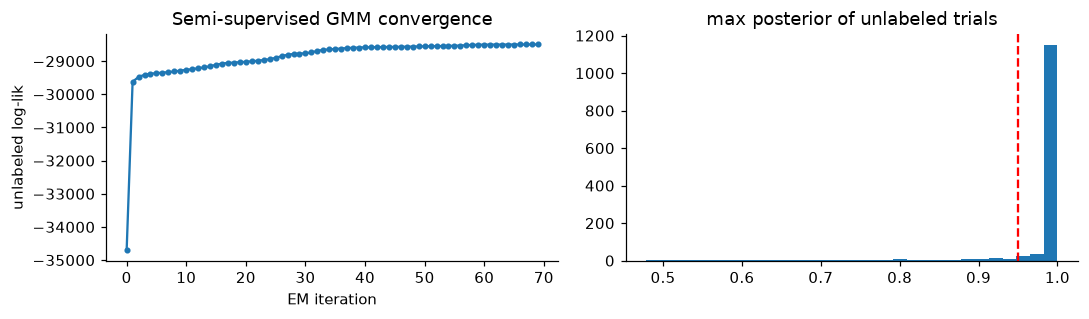

iterations: 70 | fraction of unlabeled pool with posterior ≥ 0.95: 0.911


In [16]:
# EM convergence of the semi-supervised GMM (unlabeled log-likelihood per iteration)
_, RU_final, combos_final, hist = ss_gmm(XL, YL, XU, npc=20, lam=1.0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hist, "o-", ms=3); ax[0].set_xlabel("EM iteration"); ax[0].set_ylabel("unlabeled log-lik"); ax[0].set_title("Semi-supervised GMM convergence")
ax[1].hist(RU_final.max(1), bins=30); ax[1].axvline(0.95, c="r", ls="--"); ax[1].set_title("max posterior of unlabeled trials")
plt.tight_layout(); plt.savefig(FIG + "p1_ssgmm.png", bbox_inches="tight"); plt.show()
print("iterations:", len(hist), "| fraction of unlabeled pool with posterior ≥ 0.95:", round((RU_final.max(1) >= 0.95).mean(), 3))

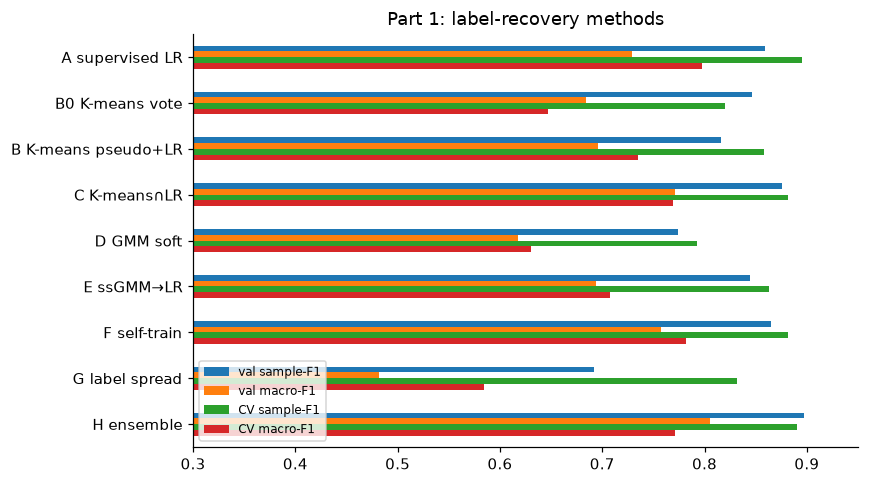

,val sample-F1,val macro-F1,CV sample-F1,CV macro-F1
A supervised LR,0.8590,0.7291,0.8957,0.7979
B0 K-means vote,0.8462,0.6844,0.8195,0.6469
B K-means pseudo+LR,0.8162,0.6963,0.8579,0.7347
C K-means∩LR,0.8761,0.7709,0.8818,0.7688
D GMM soft,0.7744,0.6174,0.7924,0.6305
E ssGMM→LR,0.8440,0.6936,0.8630,0.7074
F self-train,0.8654,0.7578,0.8818,0.7817
G label spread,0.6923,0.4816,0.8319,0.5843
H ensemble,0.8974,0.8058,0.8900,0.7714


In [17]:
# Summary figure: best setting of each family
best = {"A supervised LR": "A  supervised LR C=0.1",
        "B0 K-means vote": "B0 K-means cluster vote only K=40",
        "B K-means pseudo+LR": "B  K-means cluster-then-label K=40 w_u=0.3",
        "C K-means∩LR": "C  K-means ∩ LR agreement K=20",
        "D GMM soft": "D  GMM soft labels K=20",
        "E ssGMM→LR": "E  semi-sup GMM → pseudo-labels → LR npc=20 conf=0.95",
        "F self-train": "F  self-training LR thr=0.95",
        "G label spread": "G  label spreading k=20",
        "H ensemble": "H  ensemble (A + C + E)"}
summ = p1_table.loc[list(best.values()), ["val sample-F1", "val macro-F1", "CV sample-F1", "CV macro-F1"]]
summ.index = list(best.keys())
ax = summ.plot.barh(figsize=(8, 4.5)); ax.set_xlim(0.3, 0.95); ax.invert_yaxis(); ax.legend(fontsize=8, loc="lower left")
ax.set_title("Part 1: label-recovery methods")
plt.tight_layout(); plt.savefig(FIG + "p1_methods.png", bbox_inches="tight"); plt.show()
summ.round(4)

**Takeaways.**
1. Clustering alone (B0, D, G) does much worse than the supervised LR, which matches the weak cluster structure
   seen in 1.4. Rare reasons (Funding: 8 labeled positives) get swamped inside Recruitment-dominated clusters,
   which is why macro-F1 suffers most.
2. Plain cluster-then-label (B) adds a lot of label noise and *hurts* the LR it feeds. Pseudo-labels help only when
   they are **filtered**, either by agreement between the clusters and the classifier (C) or by classifier
   confidence (F). Pseudo-labels then act as a regulariser that fills in the regions of embedding space the 157
   early labeled trials do not cover.
3. The semi-supervised GMM (E0/E) converges reliably: 70 EM iterations, with 91% of unlabeled trials at
   posterior ≥ 0.95. But a Gaussian per label-set with a shared covariance is too rigid for this space, so its
   confident pseudo-labels are confidently wrong for some trials. Setting λ = 0 (labeled data only) is often better
   than λ = 1. This is the classic failure of EM when the generative model is misspecified (Nigam et al., 2000).
4. The validation set is tiny (one trial ≈ 1.3 points of sample-F1), so we look at validation and CV together.
   The **ensemble (H)** has the best validation scores (sample-F1 0.897, macro-F1 0.806), and its CV score is within
   noise of the best. Averaging three models with different error patterns gives the largest gain on Funding and
   Other, the rare classes. We select H.

## 1.6 Feature choices
The reason embeddings encode the stopping text itself. The other columns describe *what* was tested, not
*why* it stopped. We test whether they add anything to the selected configuration (supervised LR part,
C=0.1).

In [18]:
from sklearn.preprocessing import MultiLabelBinarizer
txt1 = lambda df: df[["criteria", "diseases_cleaned", "drugs"]].fillna("").agg(" ".join, axis=1)
tv1 = TfidfVectorizer(min_df=3, max_features=20000, stop_words="english", sublinear_tf=True).fit(pd.concat([txt1(reason_train), txt1(reason_test)]))
svd1 = TruncatedSVD(50, random_state=SEED).fit(tv1.transform(pd.concat([txt1(reason_train), txt1(reason_test)])))
sc_txt = StandardScaler().fit(svd1.transform(tv1.transform(txt1(reason_train))))
f_text = lambda df: sc_txt.transform(svd1.transform(tv1.transform(txt1(df))))
f_year = lambda df: ((df.start_year.values - 2005) / 3)[:, None]
mlb_act = MultiLabelBinarizer().fit(pd.concat([reason_train, reason_test]).drug_actions.fillna("").str.split(";"))
f_drug = lambda df: np.hstack([df.matched_drugs.notna().values[:, None].astype(float), mlb_act.transform(df.drug_actions.fillna("").str.split(";"))])
mlb_pw = MultiLabelBinarizer().fit(pd.concat([reason_train, reason_test]).drug_pathways.fillna("").str.split(";"))
lvl0 = set(pathway_catalog.reactome_id[pathway_catalog.pathway_level == 0])
f_pw0 = lambda df: mlb_pw.transform(df.drug_pathways.fillna("").str.split(";"))[:, [c in lvl0 for c in mlb_pw.classes_]]

feat_sets = {"embeddings only": [],
             "+ start_year": [f_year],
             "+ criteria/disease/drug text (TF-IDF→SVD-50)": [f_text],
             "+ drug match flag + drug actions": [f_drug],
             "+ level-0 Reactome pathways": [f_pw0],
             "+ everything": [f_year, f_text, f_drug, f_pw0]}
rows = []
for name, fs in feat_sets.items():
    A = lambda X, df: np.hstack([X] + [f(df) for f in fs])
    yv = at_least_one(fit_lr(A(XL, reason_train[labeled]), YL, 0.1)(A(X_val, reason_val)))
    rows.append({"features": name, "#dims": A(X_val, reason_val).shape[1],
                 "val sample-F1": f1_score(Yva, yv, average="samples"), "val macro-F1": f1_score(Yva, yv, average="macro")})
p1_feat = pd.DataFrame(rows).set_index("features").round(4)
p1_feat

,#dims,val sample-F1,val macro-F1
features,,,
embeddings only,150,0.8590,0.7291
+ start_year,151,0.8526,0.7462
+ criteria/disease/drug text (TF-IDF→SVD-50),200,0.8718,0.7533
+ drug match flag + drug actions,180,0.8632,0.7335
+ level-0 Reactome pathways,179,0.8632,0.7453
+ everything,260,0.8611,0.7492


No extra feature group gives a reliable gain. The text-SVD block changes the predictions of about one validation
trial (+0.013), and using everything is worse than the best single addition. The reason embeddings encode the
stopping text itself. Eligibility criteria, diseases and drugs describe *what* was tested, not *why* it stopped,
so with 157 labeled trials the 30–110 extra dimensions mostly add variance. `start_year` lowers sample-F1 and is
risky under the temporal shift: it learns the early-trial ⇒ Recruitment pattern of the labeled set, which will not
hold for the 2010–2016 test trials. We therefore keep **embeddings only**.

## 1.7 Final Part 1 model, recovered labels and test predictions
The selected ensemble (H) is evaluated on validation below (trained on the 157 labeled trials only). For the test
submission and for recovering the masked training labels, we refit it on the 235 labeled trials (train + val), using
the same unlabeled pool. This is a standard refit after model selection.

In [19]:
final_val = at_least_one(m_ensemble(XL, YL, XU)(X_val))
print("Selected model (H) on validation — sample-F1:", round(f1_score(Yva, final_val, average="samples"), 4),
      " macro-F1:", round(f1_score(Yva, final_val, average="macro"), 4))
p1_final_per_label = pd.DataFrame({"baseline LR": f1_score(Yva, val_pred, average=None, zero_division=0),
                                   "ensemble H": f1_score(Yva, final_val, average=None)}, index=labels).round(4)
print(p1_final_per_label)

final_reason_model = m_ensemble(XP, YP, XU)
P_test1 = final_reason_model(X_test)
Y_test1 = at_least_one(P_test1)
Y_unlab = at_least_one(final_reason_model(X_train[~labeled]))
print("\nPredicted prevalence  test:", dict(zip(labels, Y_test1.mean(0).round(3))))
print("Recovered prevalence unlabeled train:", dict(zip(labels, Y_unlab.mean(0).round(3))))

Selected model (H) on validation — sample-F1: 0.8974  macro-F1: 0.8058
             baseline LR  ensemble H
Safety            0.8571      0.8889
Funding           0.2857      0.7500
Efficacy          0.8276      0.8000
Recruitment       0.9796      0.9899
Other             0.5833      0.6000



Predicted prevalence  test: {'Safety': np.float64(0.183), 'Funding': np.float64(0.032), 'Efficacy': np.float64(0.141), 'Recruitment': np.float64(0.58), 'Other': np.float64(0.228)}
Recovered prevalence unlabeled train: {'Safety': np.float64(0.118), 'Funding': np.float64(0.025), 'Efficacy': np.float64(0.143), 'Recruitment': np.float64(0.687), 'Other': np.float64(0.169)}


In [20]:
# recovered (augmented) training labels
reason_train_aug = reason_train.copy()
reason_train_aug.loc[~labeled, labels] = Y_unlab
reason_train_aug["label_source"] = np.where(labeled, "true", "recovered")
reason_train_aug[["ID", "label_source"] + labels].to_csv("part1_train_recovered_labels.csv", index=False)

# Kaggle submission
part1_submission = reason_test[["ID"]].copy()
part1_submission["Predicted"] = [" ".join(l for l, v in zip(labels, r) if v) for r in Y_test1]
part1_submission.to_csv("part1_submission.csv", index=False)
part1_submission.head()

,ID,Predicted
0,TR00756,Efficacy
1,TR05267,Safety
2,TR10354,Safety
3,TR01930,Recruitment
4,TR01046,Other


In [21]:
# Reason lookup used by Part 2's error analysis (true labels where available, predicted otherwise)
reason_lookup = pd.concat([
    reason_train_aug[["ID"] + labels].assign(source=np.where(labeled, "true", "predicted")),
    reason_val[["ID"] + labels].assign(source="true"),
    pd.DataFrame(Y_test1, columns=labels).assign(ID=reason_test.ID.values, source="predicted"),
]).set_index("ID")
reason_lookup.source.value_counts()

source
predicted    1326
true          235
Name: count, dtype: int64

# Part 2: Trial outcomes

## 2.1 Baseline (starter code): per-phase bag-of-words LR

In [22]:
text_columns = ["criteria", "diseases_cleaned", "drugs", "icdcodes"]
phases = ["I", "II", "III"]

def trial_text(df):
    return df[text_columns].fillna("").agg(" ".join, axis=1)

print(pd.concat({"train": outcome_train.groupby("phase").label.agg(["size", "mean"]),
                 "val": outcome_val.groupby("phase").label.agg(["size", "mean"])}, axis=1).round(3))

      train         val       
       size   mean size   mean
phase                         
I      1012  0.566  149  0.570
II     3950  0.477  501  0.471
III    3075  0.653  363  0.661


In [23]:
val_results = outcome_val[["ID", "trial_id", "phase", "label"]].copy()
part2_submission = outcome_test[["ID"]].copy()
scores = []

for phase in ["I", "II", "III"]:
    train = outcome_train[outcome_train["phase"] == phase]
    val = outcome_val[outcome_val["phase"] == phase]
    test = outcome_test[outcome_test["phase"] == phase]

    vectorizer = CountVectorizer(binary=True, min_df=3, max_features=20000)
    X_train_phase = vectorizer.fit_transform(trial_text(train))
    X_val_phase = vectorizer.transform(trial_text(val))
    X_test_phase = vectorizer.transform(trial_text(test))

    model = LogisticRegression(max_iter=500, solver="liblinear", random_state=42)
    model.fit(X_train_phase, train["label"])

    prediction = model.predict(X_val_phase)
    probability = model.predict_proba(X_val_phase)[:, 1]
    val_results.loc[val.index, "prediction"] = prediction
    val_results.loc[val.index, "probability"] = probability
    part2_submission.loc[test.index, "label"] = model.predict_proba(X_test_phase)[:, 1]

    scores.append({
        "Phase": phase,
        "F1": f1_score(val["label"], prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(val["label"], probability),
        "PR-AUC": average_precision_score(val["label"], probability),
        "Log Loss": log_loss(val["label"], probability)
    })

baseline_scores = pd.DataFrame(scores)
baseline_part2_submission = part2_submission.copy()
baseline_scores.round(4)

,Phase,F1,ROC-AUC,PR-AUC,Log Loss
0,I,0.7006,0.7029,0.7543,0.8791
1,II,0.6141,0.6633,0.6383,1.0603
2,III,0.7739,0.7049,0.8152,0.8808


## 2.2 Error analysis by stopping reason
For each **unsuccessful** validation row (label = 0) we look up its `trial_id` among the Part 1 IDs.
Trials in Part 1 train-labeled or Part 1 val have **true** reason labels. Trials in Part 1 train-unlabeled or Part 1
test have **predicted** labels from our Part 1 model. Unmatched trials form the "no recorded stopping reason" group.
A trial can count toward several reasons. Each phase is analysed separately; within a phase each trial appears once.

In [24]:
def reason_error_table(results, prob_col="probability", thr=0.5):
    failed = results[results["label"] == 0].copy()
    failed["pred_success"] = (failed[prob_col] >= thr).astype(int)
    m = failed.join(reason_lookup, on="trial_id")
    rows = []
    for ph in phases:
        f = m[m.phase == ph]
        assert f.trial_id.is_unique
        groups = {r: f[f[r] == 1] for r in labels}
        groups["No recorded stopping reason"] = f[f.source.isna()]
        for g, sub in groups.items():
            rows.append({"phase": ph, "group": g, "n trials": len(sub),
                         "n true / predicted reason": "—" if g.startswith("No") else
                             f"{(sub.source == 'true').sum()} / {(sub.source == 'predicted').sum()}",
                         "frac predicted successful": sub.pred_success.mean() if len(sub) else np.nan})
        rows.append({"phase": ph, "group": "All failed trials", "n trials": len(f), "n true / predicted reason": "",
                     "frac predicted successful": f.pred_success.mean()})
    return pd.DataFrame(rows)

failed_val = val_results[val_results["label"] == 0].copy()
err_base = reason_error_table(val_results)
err_base.round(3)

,phase,group,n trials,n true / predicted reason,frac predicted successful
0,I,Safety,9,1 / 8,0.444
1,I,Funding,4,1 / 3,0.500
2,I,Efficacy,2,0 / 2,0.500
3,I,Recruitment,23,2 / 21,0.391
4,I,Other,3,0 / 3,0.333
5,I,No recorded stopping reason,28,—,0.571
6,I,All failed trials,64,,0.469
7,II,Safety,13,1 / 12,0.615
8,II,Funding,4,1 / 3,0.250
9,II,Efficacy,11,0 / 11,0.273


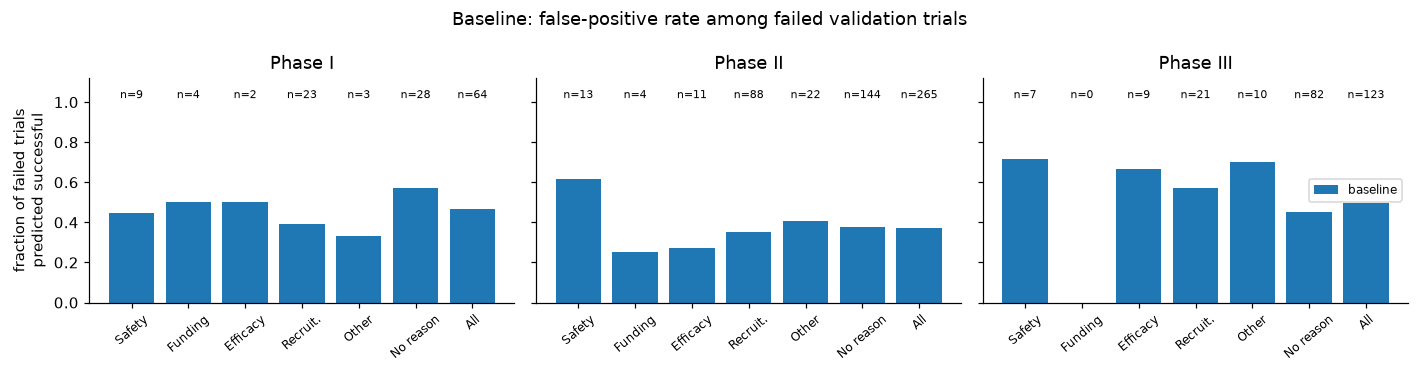

In [25]:
def plot_err(tabs, names, fname, title):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
    order = labels + ["No recorded stopping reason", "All failed trials"]
    for ax, ph in zip(axes, phases):
        w = 0.8 / len(tabs)
        for i, (t, n) in enumerate(zip(tabs, names)):
            s = t[t.phase == ph].set_index("group").reindex(order)
            ax.bar(np.arange(len(order)) + i * w, s["frac predicted successful"], w, label=n)
            if i == 0:
                for x, cnt in enumerate(s["n trials"]):
                    ax.text(x + w * (len(tabs) - 1) / 2, 1.02, f"n={cnt}", ha="center", fontsize=7)
        ax.set_xticks(np.arange(len(order)) + w * (len(tabs) - 1) / 2)
        ax.set_xticklabels(["Safety", "Funding", "Efficacy", "Recruit.", "Other", "No reason", "All"], rotation=40, fontsize=8)
        ax.set_title(f"Phase {ph}"); ax.set_ylim(0, 1.12)
    axes[0].set_ylabel("fraction of failed trials\npredicted successful"); axes[-1].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG + fname, bbox_inches="tight"); plt.show()

plot_err([err_base], ["baseline"], "p2_err_baseline.png", "Baseline: false-positive rate among failed validation trials")

## 2.3 Model exploration
Every configuration is trained per phase on `outcome_train` and scored on `outcome_val`. Reason labels and
embeddings are **never** used as inputs here.

Candidates:
* LR on binary BoW with tuned regularisation (the starter uses C=1, which badly overfits ~20k features × 1–4k rows)
* TF-IDF unigrams / 1–2-grams (sublinear tf, English stop words)
* separate TF-IDF blocks per field (criteria, diseases, drugs, ICD codes with chapter-prefix tokens)
* drug-knowledge features (Reactome pathways, targets, actions; RDKit Morgan fingerprints) and `start_year`
* Multinomial NB, cosine kNN
* a **pooled phase-augmented LR**: one model on all phases with shared features plus a phase-specific copy of every
  feature (Daumé III, 2007). Phase I (1,012 training rows) can then borrow strength from phases II/III, while each
  phase still gets its own weights.

In [26]:
p2_rows = []
def metrics(y, p, thr=0.5):
    return {"F1": f1_score(y, p >= thr, zero_division=0), "ROC-AUC": roc_auc_score(y, p),
            "PR-AUC": average_precision_score(y, p), "Log Loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6))}

def run_phasewise(name, make, train_df=outcome_train, eval_df=outcome_val, record=True, verbose=True):
    """make(train_phase_df, eval_phase_df, phase) -> probabilities for eval rows."""
    probs = pd.Series(index=eval_df.index, dtype=float); res = {}
    for ph in phases:
        a, b = train_df[train_df.phase == ph], eval_df[eval_df.phase == ph]
        probs[b.index] = make(a, b, ph)
        res[ph] = metrics(b.label.values, probs[b.index].values)
    r = pd.DataFrame(res).T
    if record:
        p2_rows.append({"model": name, **{f"{k} {ph}": r.loc[ph, k] for ph in phases for k in r.columns},
                        **{f"mean {k}": r[k].mean() for k in r.columns}})
    if verbose:
        print(f"{name:52s} " + "  ".join(f"{ph}: F1={r.loc[ph,'F1']:.3f} AUC={r.loc[ph,'ROC-AUC']:.3f} LL={r.loc[ph,'Log Loss']:.3f}" for ph in phases)
              + f" | mean AUC={r['ROC-AUC'].mean():.4f} LL={r['Log Loss'].mean():.4f}")
    return probs

bow = lambda: CountVectorizer(binary=True, min_df=3, max_features=20000)
tfidf_uni = lambda: TfidfVectorizer(min_df=3, max_features=50000, sublinear_tf=True, stop_words="english")
tfidf_bi = lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100000, sublinear_tf=True, stop_words="english")

def make_text_lr(vec, C):
    def make(a, b, ph):
        v = vec(); m = LogisticRegression(C=C, max_iter=3000, solver="liblinear").fit(v.fit_transform(trial_text(a)), a.label)
        return m.predict_proba(v.transform(trial_text(b)))[:, 1]
    return make

_ = run_phasewise("baseline: BoW LR C=1", make_text_lr(bow, 1))
for C in [0.01, 0.03, 0.1, 0.3]:
    _ = run_phasewise(f"BoW LR C={C}", make_text_lr(bow, C))
for C in [1, 3, 10]:
    _ = run_phasewise(f"TF-IDF unigram LR C={C}", make_text_lr(tfidf_uni, C))
for C in [1, 3, 10]:
    _ = run_phasewise(f"TF-IDF 1-2gram LR C={C}", make_text_lr(tfidf_bi, C))

baseline: BoW LR C=1                                 I: F1=0.701 AUC=0.703 LL=0.879  II: F1=0.614 AUC=0.663 LL=1.060  III: F1=0.774 AUC=0.705 LL=0.881 | mean AUC=0.6904 LL=0.9401


BoW LR C=0.01                                        I: F1=0.781 AUC=0.757 LL=0.597  II: F1=0.622 AUC=0.712 LL=0.617  III: F1=0.797 AUC=0.744 LL=0.561 | mean AUC=0.7374 LL=0.5918


BoW LR C=0.03                                        I: F1=0.751 AUC=0.746 LL=0.595  II: F1=0.631 AUC=0.704 LL=0.636  III: F1=0.807 AUC=0.742 LL=0.565 | mean AUC=0.7304 LL=0.5985


BoW LR C=0.1                                         I: F1=0.720 AUC=0.728 LL=0.634  II: F1=0.626 AUC=0.690 LL=0.701  III: F1=0.783 AUC=0.733 LL=0.605 | mean AUC=0.7173 LL=0.6468


BoW LR C=0.3                                         I: F1=0.689 AUC=0.713 LL=0.724  II: F1=0.616 AUC=0.675 LL=0.828  III: F1=0.779 AUC=0.721 LL=0.697 | mean AUC=0.7031 LL=0.7498


TF-IDF unigram LR C=1                                I: F1=0.754 AUC=0.759 LL=0.598  II: F1=0.629 AUC=0.724 LL=0.607  III: F1=0.806 AUC=0.770 LL=0.539 | mean AUC=0.7511 LL=0.5812


TF-IDF unigram LR C=3                                I: F1=0.753 AUC=0.751 LL=0.585  II: F1=0.619 AUC=0.719 LL=0.609  III: F1=0.806 AUC=0.768 LL=0.536 | mean AUC=0.7462 LL=0.5765


TF-IDF unigram LR C=10                               I: F1=0.736 AUC=0.740 LL=0.606  II: F1=0.613 AUC=0.709 LL=0.650  III: F1=0.809 AUC=0.750 LL=0.572 | mean AUC=0.7329 LL=0.6092


TF-IDF 1-2gram LR C=1                                I: F1=0.763 AUC=0.763 LL=0.601  II: F1=0.630 AUC=0.728 LL=0.606  III: F1=0.813 AUC=0.780 LL=0.538 | mean AUC=0.7570 LL=0.5815


TF-IDF 1-2gram LR C=3                                I: F1=0.742 AUC=0.766 LL=0.580  II: F1=0.615 AUC=0.724 LL=0.604  III: F1=0.811 AUC=0.780 LL=0.526 | mean AUC=0.7568 LL=0.5700


TF-IDF 1-2gram LR C=10                               I: F1=0.739 AUC=0.762 LL=0.579  II: F1=0.601 AUC=0.718 LL=0.633  III: F1=0.823 AUC=0.772 LL=0.542 | mean AUC=0.7508 LL=0.5843


In [27]:
def make_mnb(vec, alpha):
    def make(a, b, ph):
        v = vec(); m = MultinomialNB(alpha=alpha).fit(v.fit_transform(trial_text(a)), a.label)
        return m.predict_proba(v.transform(trial_text(b)))[:, 1]
    return make

def make_knn(k):
    def make(a, b, ph):
        v = tfidf_uni(); m = KNeighborsClassifier(k, metric="cosine", weights="distance").fit(v.fit_transform(trial_text(a)), a.label)
        return m.predict_proba(v.transform(trial_text(b)))[:, 1]
    return make

counts = lambda: CountVectorizer(min_df=3, max_features=20000)
for al in [1, 10]:
    _ = run_phasewise(f"Multinomial NB counts α={al}", make_mnb(counts, al))
for al in [0.1, 0.3, 1]:
    _ = run_phasewise(f"Multinomial NB TF-IDF α={al}", make_mnb(tfidf_uni, al))
for k in [25, 75, 150]:
    _ = run_phasewise(f"kNN cosine TF-IDF k={k}", make_knn(k))

Multinomial NB counts α=1                            I: F1=0.684 AUC=0.717 LL=3.530  II: F1=0.636 AUC=0.694 LL=4.129  III: F1=0.784 AUC=0.732 LL=3.294 | mean AUC=0.7142 LL=3.6511


Multinomial NB counts α=10                           I: F1=0.712 AUC=0.710 LL=3.025  II: F1=0.633 AUC=0.691 LL=4.128  III: F1=0.809 AUC=0.707 LL=3.263 | mean AUC=0.7028 LL=3.4720


Multinomial NB TF-IDF α=0.1                          I: F1=0.679 AUC=0.722 LL=0.628  II: F1=0.610 AUC=0.701 LL=0.797  III: F1=0.789 AUC=0.765 LL=0.737 | mean AUC=0.7294 LL=0.7209


Multinomial NB TF-IDF α=0.3                          I: F1=0.705 AUC=0.727 LL=0.602  II: F1=0.605 AUC=0.700 LL=0.759  III: F1=0.796 AUC=0.761 LL=0.693 | mean AUC=0.7291 LL=0.6848


Multinomial NB TF-IDF α=1                            I: F1=0.749 AUC=0.723 LL=0.602  II: F1=0.600 AUC=0.698 LL=0.711  III: F1=0.805 AUC=0.750 LL=0.644 | mean AUC=0.7238 LL=0.6524


kNN cosine TF-IDF k=25                               I: F1=0.739 AUC=0.749 LL=0.589  II: F1=0.615 AUC=0.706 LL=0.620  III: F1=0.816 AUC=0.768 LL=0.592 | mean AUC=0.7411 LL=0.6007


kNN cosine TF-IDF k=75                               I: F1=0.745 AUC=0.717 LL=0.617  II: F1=0.605 AUC=0.716 LL=0.614  III: F1=0.805 AUC=0.770 LL=0.562 | mean AUC=0.7342 LL=0.5980


kNN cosine TF-IDF k=150                              I: F1=0.724 AUC=0.705 LL=0.636  II: F1=0.609 AUC=0.712 LL=0.619  III: F1=0.798 AUC=0.754 LL=0.575 | mean AUC=0.7234 LL=0.6100


### Field-wise TF-IDF and drug-knowledge features

In [28]:
def icd_text(df):  # add 3-character ICD chapter prefixes (E11.65 -> "E11 E11.65") so related codes share a token
    return df.icdcodes.fillna("").str.replace(r"([A-Z][0-9]{2})\.", r"\1 \1.", regex=True)

def drug_text(df):
    return (df.drug_pathways.fillna("").str.replace(";", " ") + " "
            + df.drug_targets.fillna("").apply(lambda s: " ".join("TGT_" + t for t in s.split(";") if t)) + " "
            + df.drug_actions.fillna("").apply(lambda s: " ".join("ACT_" + t.replace(" ", "_") for t in s.split(";") if t)))

class FieldFeaturizer:
    """Separate TF-IDF per field, weighted and concatenated. Optional drug-knowledge / year / fingerprint blocks."""
    def __init__(self, weights=None, drug=0.0, year=0.0, fp=0.0):
        self.w = weights or {"criteria": 1.0, "diseases": 0.5, "drugs": 0.5, "icd": 0.5}
        self.drug, self.year, self.fp = drug, year, fp
    def _get(self, df, k):
        return {"criteria": df.criteria, "diseases": df.diseases_cleaned, "drugs": df.drugs, "icd": icd_text(df),
                "drugk": drug_text(df)}[k].fillna("")
    def fit(self, df):
        self.v = {"criteria": tfidf_bi(),
                  "diseases": TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                  "drugs": TfidfVectorizer(min_df=2, sublinear_tf=True),
                  "icd": TfidfVectorizer(min_df=2, token_pattern=r"[A-Z][0-9]{2}(?:\.[0-9A-Z]+)?", lowercase=False)}
        if self.drug: self.v["drugk"] = TfidfVectorizer(min_df=3, token_pattern=r"[^ ]+", lowercase=False, sublinear_tf=True)
        for k, v in self.v.items(): v.fit(self._get(df, k))
        return self
    def transform(self, df):
        blocks = [self.w.get(k, self.drug) * v.transform(self._get(df, k)) for k, v in self.v.items()]
        if self.year: blocks.append(sp.csr_matrix(self.year * ((df.start_year.fillna(2007).values - 2007) / 3)[:, None]))
        if self.fp: blocks.append(self.fp * sp.csr_matrix(fingerprints(df)))
        return sp.hstack(blocks).tocsr()

# RDKit Morgan fingerprints (radius 2, 1024 bits, OR over a trial's drugs; zeros if no matched drug), cached by SMILES string
try:
    from rdkit import Chem, RDLogger
    from rdkit.Chem import rdFingerprintGenerator
    RDLogger.DisableLog("rdApp.*")
    _gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
    _fp_cache = {}
    def _trial_fp(s):
        if pd.isna(s): return np.zeros(1024, dtype=np.float32)
        if s not in _fp_cache:
            fps = [_gen.GetFingerprintAsNumPy(m) for x in s.split(";") if (m := Chem.MolFromSmiles(x)) is not None]
            _fp_cache[s] = (np.max(fps, axis=0) if fps else np.zeros(1024)).astype(np.float32)
        return _fp_cache[s]
    def fingerprints(df):
        F = np.vstack(df.drug_smiles.apply(_trial_fp).values)
        return F / np.sqrt(np.maximum(F.sum(1, keepdims=True), 1))     # L2-normalise like the TF-IDF rows
    HAVE_RDKIT = True
except ImportError:
    HAVE_RDKIT = False
print("RDKit available:", HAVE_RDKIT,
      "| rows with a matched drug (train):", round(outcome_train.drug_smiles.notna().mean(), 3))

def make_field_lr(C=1.0, **fk):
    def make(a, b, ph):
        f = FieldFeaturizer(**fk).fit(a)
        m = LogisticRegression(C=C, max_iter=3000, solver="liblinear").fit(f.transform(a), a.label)
        return m.predict_proba(f.transform(b))[:, 1]
    return make

for C in [1, 3]:
    _ = run_phasewise(f"field-wise TF-IDF LR C={C}", make_field_lr(C))
_ = run_phasewise("field-wise TF-IDF + start_year LR C=1", make_field_lr(1, year=1.0))
_ = run_phasewise("field-wise TF-IDF + drug pathways/targets/actions LR C=1", make_field_lr(1, drug=0.3))
if HAVE_RDKIT:
    _ = run_phasewise("field-wise TF-IDF + Morgan fingerprints LR C=1", make_field_lr(1, fp=0.3))

RDKit available: True | rows with a matched drug (train): 0.457


field-wise TF-IDF LR C=1                             I: F1=0.724 AUC=0.764 LL=0.591  II: F1=0.629 AUC=0.725 LL=0.605  III: F1=0.814 AUC=0.776 LL=0.531 | mean AUC=0.7547 LL=0.5756


field-wise TF-IDF LR C=3                             I: F1=0.733 AUC=0.759 LL=0.586  II: F1=0.632 AUC=0.720 LL=0.614  III: F1=0.806 AUC=0.773 LL=0.534 | mean AUC=0.7506 LL=0.5778


field-wise TF-IDF + start_year LR C=1                I: F1=0.736 AUC=0.758 LL=0.590  II: F1=0.633 AUC=0.722 LL=0.606  III: F1=0.820 AUC=0.767 LL=0.537 | mean AUC=0.7489 LL=0.5778


field-wise TF-IDF + drug pathways/targets/actions LR C=1 I: F1=0.718 AUC=0.760 LL=0.590  II: F1=0.617 AUC=0.724 LL=0.606  III: F1=0.811 AUC=0.776 LL=0.531 | mean AUC=0.7533 LL=0.5757


field-wise TF-IDF + Morgan fingerprints LR C=1       I: F1=0.718 AUC=0.760 LL=0.590  II: F1=0.621 AUC=0.725 LL=0.606  III: F1=0.815 AUC=0.775 LL=0.531 | mean AUC=0.7530 LL=0.5754


### Pooled phase-augmented LR

In [29]:
def phase_augment(X, ph_arr):
    """[shared | phase-I copy | phase-II copy | phase-III copy | phase one-hot]"""
    blocks = [X] + [sp.diags((ph_arr == p).astype(float)) @ X for p in phases]
    onehot = sp.csr_matrix(np.column_stack([(ph_arr == p).astype(float) for p in phases]))
    return sp.hstack(blocks + [onehot]).tocsr()

class PooledPhaseLR:
    def __init__(self, C=1.0, class_weight=None, **fk):
        self.C, self.cw, self.fk = C, class_weight, fk
    def fit(self, df):
        self.f = FieldFeaturizer(**self.fk).fit(df)
        self.m = LogisticRegression(C=self.C, max_iter=5000, solver="liblinear", class_weight=self.cw).fit(
            phase_augment(self.f.transform(df), df.phase.values), df.label)
        return self
    def predict_proba(self, df):
        return self.m.predict_proba(phase_augment(self.f.transform(df), df.phase.values))[:, 1]

pooled_cache = {}
def make_pooled(C=1.0, class_weight=None, train_df=outcome_train, **fk):
    key = (C, class_weight, id(train_df), tuple(sorted(fk.items())))
    def make(a, b, ph):
        if key not in pooled_cache: pooled_cache[key] = PooledPhaseLR(C, class_weight, **fk).fit(train_df)
        return pooled_cache[key].predict_proba(b)
    return make

for C in [0.3, 1, 3]:
    _ = run_phasewise(f"pooled phase-augmented field TF-IDF LR C={C}", make_pooled(C))

pooled phase-augmented field TF-IDF LR C=0.3         I: F1=0.729 AUC=0.753 LL=0.593  II: F1=0.630 AUC=0.736 LL=0.600  III: F1=0.814 AUC=0.788 LL=0.527 | mean AUC=0.7590 LL=0.5736


pooled phase-augmented field TF-IDF LR C=1           I: F1=0.727 AUC=0.758 LL=0.585  II: F1=0.645 AUC=0.737 LL=0.599  III: F1=0.815 AUC=0.789 LL=0.516 | mean AUC=0.7612 LL=0.5665


pooled phase-augmented field TF-IDF LR C=3           I: F1=0.719 AUC=0.755 LL=0.598  II: F1=0.649 AUC=0.733 LL=0.620  III: F1=0.809 AUC=0.782 LL=0.528 | mean AUC=0.7565 LL=0.5818


In [30]:
def make_ens(*makers, weights=None):
    def make(a, b, ph):
        return np.average([m(a, b, ph) for m in makers], axis=0, weights=weights)
    return make

_ = run_phasewise("ensemble: pooled LR + per-phase TF-IDF 1-2 LR", make_ens(make_pooled(1), make_text_lr(tfidf_bi, 3)))
_ = run_phasewise("ensemble: pooled LR + kNN k=75", make_ens(make_pooled(1), make_knn(75), weights=[0.7, 0.3]))
_ = run_phasewise("ensemble: pooled LR + MNB TF-IDF α=0.3", make_ens(make_pooled(1), make_mnb(tfidf_uni, 0.3), weights=[0.7, 0.3]))

ensemble: pooled LR + per-phase TF-IDF 1-2 LR        I: F1=0.733 AUC=0.769 LL=0.577  II: F1=0.632 AUC=0.735 LL=0.598  III: F1=0.809 AUC=0.790 LL=0.517 | mean AUC=0.7647 LL=0.5639


ensemble: pooled LR + kNN k=75                       I: F1=0.723 AUC=0.765 LL=0.585  II: F1=0.642 AUC=0.739 LL=0.595  III: F1=0.816 AUC=0.793 LL=0.513 | mean AUC=0.7653 LL=0.5646


ensemble: pooled LR + MNB TF-IDF α=0.3               I: F1=0.719 AUC=0.757 LL=0.580  II: F1=0.618 AUC=0.731 LL=0.605  III: F1=0.802 AUC=0.785 LL=0.524 | mean AUC=0.7576 LL=0.5699


In [31]:
p2_table = pd.DataFrame(p2_rows).set_index("model")
show = ["mean F1", "mean ROC-AUC", "mean PR-AUC", "mean Log Loss"] + [f"{k} {ph}" for ph in phases for k in ["F1", "ROC-AUC", "PR-AUC"]]
p2_table[show].round(4).sort_values("mean Log Loss")

,mean F1,mean ROC-AUC,mean PR-AUC,mean Log Loss,F1 I,ROC-AUC I,PR-AUC I,F1 II,ROC-AUC II,PR-AUC II,F1 III,ROC-AUC III,PR-AUC III
model,,,,,,,,,,,,,
ensemble: pooled LR + per-phase TF-IDF 1-2 LR,0.7248,0.7647,0.8021,0.5639,0.7333,0.7693,0.8034,0.6320,0.7347,0.7204,0.8092,0.7900,0.8826
ensemble: pooled LR + kNN k=75,0.7269,0.7653,0.8059,0.5646,0.7232,0.7645,0.8079,0.6416,0.7387,0.7254,0.8161,0.7926,0.8844
pooled phase-augmented field TF-IDF LR C=1,0.7289,0.7612,0.7983,0.5665,0.7273,0.7585,0.7991,0.6449,0.7365,0.7182,0.8145,0.7886,0.8775
ensemble: pooled LR + MNB TF-IDF α=0.3,0.7131,0.7576,0.8007,0.5699,0.7191,0.7566,0.8056,0.6178,0.7314,0.7172,0.8023,0.7849,0.8793
TF-IDF 1-2gram LR C=3,0.7227,0.7568,0.7951,0.5700,0.7416,0.7660,0.7950,0.6151,0.7243,0.7134,0.8114,0.7801,0.8770
pooled phase-augmented field TF-IDF LR C=0.3,0.7244,0.7590,0.8023,0.5736,0.7293,0.7528,0.8028,0.6297,0.7360,0.7212,0.8143,0.7881,0.8829
field-wise TF-IDF + Morgan fingerprints LR C=1,0.7182,0.7530,0.7978,0.5754,0.7182,0.7597,0.8087,0.6211,0.7247,0.7125,0.8152,0.7747,0.8724
field-wise TF-IDF LR C=1,0.7222,0.7547,0.7993,0.5756,0.7243,0.7638,0.8121,0.6286,0.7246,0.7127,0.8137,0.7758,0.8731
field-wise TF-IDF + drug pathways/targets/actions LR C=1,0.7152,0.7533,0.7981,0.5757,0.7182,0.7601,0.8079,0.6167,0.7239,0.7129,0.8107,0.7758,0.8735


## 2.4 Selected improvement and comparison with the baseline

**Selected model: pooled phase-augmented LR on field-wise TF-IDF (C=1).** Among single models it has the best mean
log loss and ROC-AUC. Ensembling it with a per-phase LR or kNN gains only ~0.002 log loss, which is within noise,
so we keep the single model. Drug-knowledge features (Reactome pathways/targets/actions, Morgan fingerprints)
and `start_year` did **not** help. Only ~46% of trials have a matched drug, and drug structure says little about
whether an endpoint is met. Two changes do most of the work:
1. **Regularisation / representation.** TF-IDF with 1–2-grams and a C picked on validation. The baseline (binary
   BoW, C=1) is so over-confident that its log loss is 0.94, *worse than predicting the base rate* (≈0.66–0.69).
2. **Sharing across phases.** Phase-specific copies on top of shared weights help phases I and II the most.

Below: per-phase metrics and the reason-group error rates of the baseline vs the improved model.

In [32]:
improved_probs = run_phasewise("SELECTED: pooled phase-augmented LR C=1", make_pooled(1), record=False)
val_results["prob_improved"] = improved_probs
imp_scores = pd.DataFrame({ph: metrics(outcome_val.label[outcome_val.phase == ph].values,
                                       improved_probs[outcome_val.phase == ph].values) for ph in phases}).T
comp = pd.concat({"baseline": baseline_scores.set_index("Phase"), "improved": imp_scores}, axis=1).round(4)
comp.loc["mean"] = comp.mean().round(4)
comp

SELECTED: pooled phase-augmented LR C=1              I: F1=0.727 AUC=0.758 LL=0.585  II: F1=0.645 AUC=0.737 LL=0.599  III: F1=0.815 AUC=0.789 LL=0.516 | mean AUC=0.7612 LL=0.5665


baseline                          improved                         
           F1 ROC-AUC  PR-AUC Log Loss       F1 ROC-AUC  PR-AUC Log Loss
I      0.7006  0.7029  0.7543   0.8791   0.7273  0.7585  0.7991   0.5849
II     0.6141  0.6633  0.6383   1.0603   0.6449  0.7365  0.7182   0.5990
III    0.7739  0.7049  0.8152   0.8808   0.8145  0.7886  0.8775   0.5155
mean   0.6962  0.6904  0.7359   0.9401   0.7289  0.7612  0.7983   0.5665

In [33]:
err_imp = reason_error_table(val_results, "prob_improved")
err_cmp = err_base.rename(columns={"frac predicted successful": "baseline"}).merge(
    err_imp[["phase", "group", "frac predicted successful"]].rename(columns={"frac predicted successful": "improved"}),
    on=["phase", "group"])
err_cmp.round(3)

,phase,group,n trials,n true / predicted reason,baseline,improved
0,I,Safety,9,1 / 8,0.444,0.556
1,I,Funding,4,1 / 3,0.500,0.000
2,I,Efficacy,2,0 / 2,0.500,1.000
3,I,Recruitment,23,2 / 21,0.391,0.391
4,I,Other,3,0 / 3,0.333,0.333
5,I,No recorded stopping reason,28,—,0.571,0.429
6,I,All failed trials,64,,0.469,0.422
7,II,Safety,13,1 / 12,0.615,0.385
8,II,Funding,4,1 / 3,0.250,0.000
9,II,Efficacy,11,0 / 11,0.273,0.455


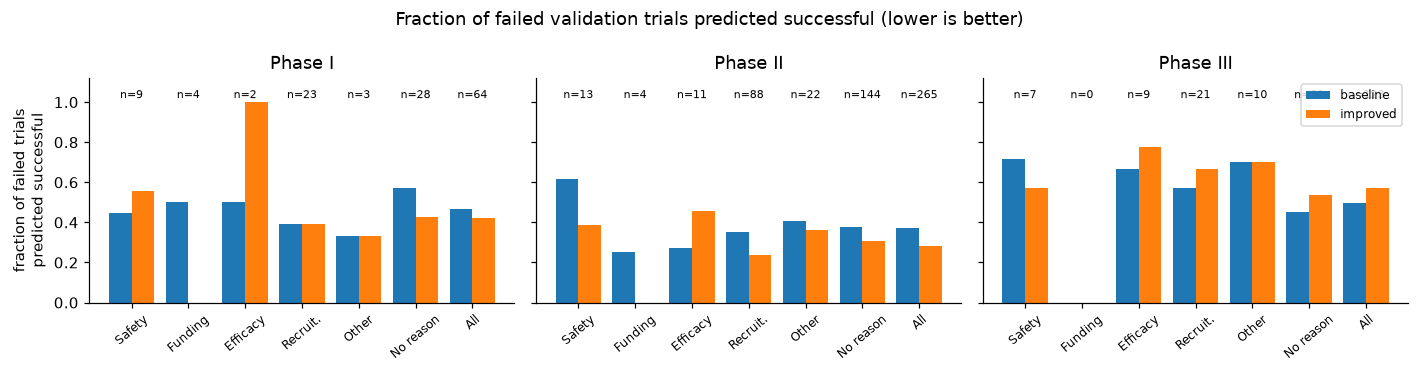

In [34]:
plot_err([err_base, err_imp], ["baseline", "improved"], "p2_err_compare.png",
         "Fraction of failed validation trials predicted successful (lower is better)")

**Reading the error table.**
* **Most failed trials have no recorded stopping reason.** They ran to completion and missed their endpoint, and
  they are 44–67% of failed trials per phase. Their text looks like any other completed trial, so they make up the
  largest share of false positives.
* **Trials stopped for Recruitment** are the largest reason group, and the improved model reduces their false
  positives most in Phase II (0.35 → 0.24, n = 88). Small, single-site, narrowly specified trials have distinctive
  criteria text, and bigrams over that text capture it.
* **Safety and Efficacy stops in Phase III** keep high false-positive rates (0.57–0.78) under both models. These
  are large, well-designed confirmatory trials whose eligibility text is indistinguishable from successful ones.
  The failure comes from the drug's effect, which the text does not reveal.
* In Phase III the improved model predicts success more often. It is better calibrated to the 65% base rate, so its
  false-positive rate on failed trials rises (0.50 → 0.57), while F1, AUC and log loss all improve.
* **Caveats:** groups with n < 10 (Funding, Phase I Efficacy/Other) change by 0.25–0.5 when a single trial flips,
  so they carry no signal. Most reason labels here are Part 1 *predictions*, e.g. 76 of 88 Phase II Recruitment
  trials. At a Part 1 validation F1 of ~0.9 a few trials sit in the wrong group, mostly blurring the rare groups
  (Funding, Other, Safety/Efficacy confusions).

### Trade-off: decision threshold / class weighting
The error analysis shows that most mistakes on failed trials are false positives (a failed trial predicted
successful). We can cut them by moving the threshold, or by training with `class_weight="balanced"`. This trades
recall on successful trials, and therefore F1, against the false-positive rate. Log loss and AUC are unaffected
by the threshold.

              F1               FPR (failed→success)                  TPR              
phase          I     II    III                    I     II    III      I     II    III
threshold                                                                             
0.4        0.776  0.664  0.825                0.547  0.460  0.667  0.894  0.754  0.942
0.5        0.727  0.645  0.815                0.422  0.283  0.569  0.753  0.627  0.888
0.6        0.693  0.608  0.800                0.234  0.128  0.415  0.624  0.500  0.808
0.7        0.585  0.504  0.756                0.109  0.083  0.244  0.447  0.369  0.683


pooled phase-augmented LR C=1, class_weight=balanced I: F1=0.713 AUC=0.758 LL=0.589  II: F1=0.628 AUC=0.736 LL=0.600  III: F1=0.806 AUC=0.789 LL=0.515 | mean AUC=0.7609 LL=0.5685


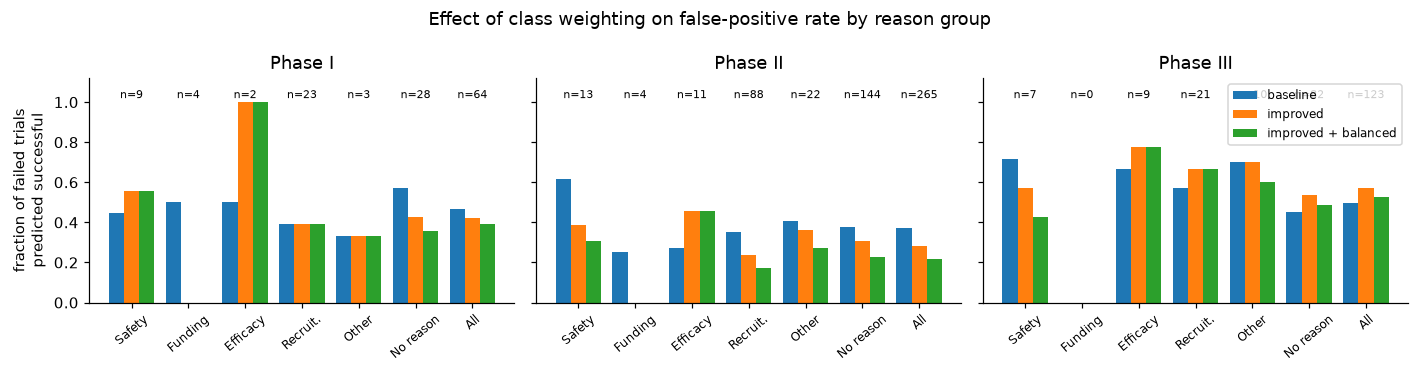

In [35]:
rows = []
for thr in [0.4, 0.5, 0.6, 0.7]:
    for ph in phases:
        msk = outcome_val.phase == ph
        y, p = outcome_val.label[msk].values, improved_probs[msk].values
        rows.append({"threshold": thr, "phase": ph, "F1": f1_score(y, p >= thr),
                     "FPR (failed→success)": (p[y == 0] >= thr).mean(), "TPR": (p[y == 1] >= thr).mean()})
thr_tab = pd.DataFrame(rows).pivot(index="threshold", columns="phase").round(3)
print(thr_tab)

bal_probs = run_phasewise("pooled phase-augmented LR C=1, class_weight=balanced", make_pooled(1, "balanced"))
val_results["prob_balanced"] = bal_probs
err_bal = reason_error_table(val_results, "prob_balanced")
plot_err([err_base, err_imp, err_bal], ["baseline", "improved", "improved + balanced"], "p2_err_balanced.png",
         "Effect of class weighting on false-positive rate by reason group")

### Temporal robustness check
The Kaggle test trials start in 2014–2021, after every training trial. To estimate how much each model loses
under this shift, we train on trials that started ≤ 2008 (train ∪ val) and evaluate on those that started
2010–2013. We also test **shrinking probabilities toward the phase base rate**, which guards log loss against
over-confidence: p' = π + s·(p − π).

In [36]:
pool = pd.concat([outcome_train, outcome_val], ignore_index=True)
early, late = pool[pool.start_year <= 2008], pool[pool.start_year >= 2010]
print("temporal split sizes:", len(early), len(late), "| success rate early/late:",
      round(early.label.mean(), 3), round(late.label.mean(), 3))
t_base = run_phasewise("[temporal] baseline BoW LR C=1", make_text_lr(bow, 1), early, late, record=False)
t_imp = run_phasewise("[temporal] pooled phase-augmented LR C=1", make_pooled(1, train_df=early), early, late, record=False)

shrink_rows = []
for s in [1.0, 0.9, 0.8, 0.7]:
    for name, pr, ref in [("random val", improved_probs, outcome_val), ("temporal", t_imp, late)]:
        ll = []
        for ph in phases:
            msk = ref.phase == ph; pi = (outcome_train if name == "random val" else early).query("phase == @ph").label.mean()
            ll.append(log_loss(ref.label[msk], pi + s * (pr[msk] - pi)))
        shrink_rows.append({"shrink s": s, "eval": name, "mean log loss": np.mean(ll)})
shrink_tab = pd.DataFrame(shrink_rows).pivot(index="shrink s", columns="eval", values="mean log loss").round(4)
shrink_tab

temporal split sizes: 6326 2290 | success rate early/late: 0.522 0.655


[temporal] baseline BoW LR C=1                       I: F1=0.748 AUC=0.562 LL=1.118  II: F1=0.632 AUC=0.630 LL=1.132  III: F1=0.812 AUC=0.660 LL=0.805 | mean AUC=0.6173 LL=1.0184


[temporal] pooled phase-augmented LR C=1             I: F1=0.793 AUC=0.625 LL=0.627  II: F1=0.724 AUC=0.732 LL=0.599  III: F1=0.876 AUC=0.728 LL=0.475 | mean AUC=0.6948 LL=0.5672


eval,random val,temporal
shrink s,,
0.7,0.5787,0.5772
0.8,0.5724,0.5717
0.9,0.5682,0.5683
1.0,0.5665,0.5672


Under the temporal split ROC-AUC drops for both models: improved 0.761 → 0.695, baseline 0.690 → 0.617. This is
the val→test gap we expect on Kaggle. The prior also shifts, from 52% success in early trials to 66% in later
ones. The baseline's over-confidence makes its temporal log loss even worse (1.02). The improved model stays at
0.567, roughly the same as its random-split value. Its lower discrimination is offset by the higher base rate,
which the model partly captures through its phase intercepts. Shrinking toward the prior does not help on either
split (the best s is 1.0), so the regularised LR is already well calibrated and we apply no shrink.

## 2.5 Final Part 2 predictions
We refit the selected model on **train ∪ val** (9,050 rows) and write `ID,label` probabilities. The shrink factor
chosen on the temporal check (1.0 = none) is applied, then probabilities are clipped to [0.02, 0.98] as a guard
against a single very costly log-loss error.

In [37]:
best_s = float(shrink_tab["temporal"].idxmin())
print("shrink factor used:", best_s)
final_outcome_model = PooledPhaseLR(C=1).fit(pool)
p_test = final_outcome_model.predict_proba(outcome_test)
prior_by_phase = pool.groupby("phase").label.mean()
pi_test = outcome_test.phase.map(prior_by_phase).values
p_test = np.clip(pi_test + best_s * (p_test - pi_test), 0.02, 0.98)

part2_submission = outcome_test[["ID"]].copy()
part2_submission["label"] = p_test
part2_submission.to_csv("part2_submission.csv", index=False)
baseline_part2_submission.to_csv("part2_submission_baseline.csv", index=False)
print(part2_submission.describe().round(3))
part2_submission.head()

shrink factor used: 1.0


          label
count  1500.000
mean      0.611
std       0.201
min       0.080
25%       0.455
50%       0.624
75%       0.773
max       0.979


,ID,label
0,TR11252_III,0.642350
1,TR08672_II,0.585126
2,TR07815_I,0.671160
3,TR08013_I,0.475696
4,TR05100_II,0.338481


## Summary tables for the report

In [38]:
print("PART 1 — selected methods (best setting per family)"); print(summ.round(4).to_string())
print("\nPART 1 — feature sets"); print(p1_feat.to_string())
print("\nPART 2 — baseline vs improved"); print(comp.to_string())
print("\nPART 2 — reason-group error rates"); print(err_cmp.round(3).to_string(index=False))

PART 1 — selected methods (best setting per family)
                     val sample-F1  val macro-F1  CV sample-F1  CV macro-F1
A supervised LR             0.8590        0.7291        0.8957       0.7979
B0 K-means vote             0.8462        0.6844        0.8195       0.6469
B K-means pseudo+LR         0.8162        0.6963        0.8579       0.7347
C K-means∩LR                0.8761        0.7709        0.8818       0.7688
D GMM soft                  0.7744        0.6174        0.7924       0.6305
E ssGMM→LR                  0.8440        0.6936        0.8630       0.7074
F self-train                0.8654        0.7578        0.8818       0.7817
G label spread              0.6923        0.4816        0.8319       0.5843
H ensemble                  0.8974        0.8058        0.8900       0.7714

PART 1 — feature sets
                                              #dims  val sample-F1  val macro-F1
features                                                                        
emb